Baseline 1 - classification. **logistic regression** on all genes → Control / COPD / ILD.

Baseline 2 - regression. **linear regression** on all genes → FEV1 % predicted.

#Load Data

In [1]:
# URLs to the series matrix files
df_train = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE47nnn/GSE47460/matrix/GSE47460-GPL14550_series_matrix.txt.gz"
df_test  = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE47nnn/GSE47460/matrix/GSE47460-GPL6480_series_matrix.txt.gz"

In [2]:
import pandas as pd
df_gpl14550 = pd.read_csv(df_train, compression='gzip', sep='\t', comment='!')
print("GPL14550 Data Shape:", df_gpl14550.shape)
display(df_gpl14550.head())

GPL14550 Data Shape: (15261, 430)


,ID_REF,GSM1149948,GSM1149950,GSM1149951,GSM1149952,GSM1149958,GSM1149962,GSM1149963,GSM1149966,GSM1149971,...,GSM1150538,GSM1150539,GSM1150540,GSM1150541,GSM1150542,GSM1150543,GSM1150544,GSM1150545,GSM1150546,GSM1150547
0,A_23_P100001,11.5722,10.6977,11.6374,11.4056,10.6067,11.6426,10.7660,11.4137,11.1908,...,11.6582,11.2451,11.2150,11.2867,10.9477,11.0966,11.5317,11.5889,11.2449,10.5108
1,A_23_P100022,8.1907,8.1716,8.3748,8.6442,8.6887,8.9591,8.5957,8.6478,8.2058,...,7.8513,8.9661,8.8689,9.2627,8.5760,8.2328,10.2103,9.0196,8.5648,7.9688
2,A_23_P100056,6.7762,7.3343,6.9591,6.3585,6.8266,6.8903,6.2069,6.7369,6.5223,...,6.3449,7.4936,5.7542,6.2713,7.0327,6.6488,7.4829,7.0914,6.7606,5.6924
3,A_23_P100074,10.0526,10.5461,10.0475,10.4067,10.4386,9.9969,9.9772,10.0965,10.0540,...,10.1425,10.0981,10.1768,10.4047,10.1957,10.0537,10.5618,9.9008,9.8891,10.4145
4,A_23_P100127,4.1446,4.7935,3.4025,5.2405,5.6410,4.4761,4.5687,5.0961,4.5922,...,5.5826,4.7711,4.3044,5.2413,5.6897,4.3149,4.3714,5.0082,3.9961,6.1176


GENES (rows: 15,261 )
- Number of unique RNA probes measured on the microarray

Samples (columns: 430)
- Number of lung tissue biopsies collected


In [3]:
df_gpl6480 = pd.read_csv(df_test, compression='gzip', sep='\t', comment='!')
print("GPL6480 Data Shape:", df_gpl6480.shape)
display(df_gpl6480.head())

GPL6480 Data Shape: (15261, 154)


,ID_REF,GSM1149949,GSM1149953,GSM1149954,GSM1149955,GSM1149956,GSM1149957,GSM1149959,GSM1149960,GSM1149961,...,GSM1150135,GSM1150136,GSM1150137,GSM1150138,GSM1150139,GSM1150140,GSM1150141,GSM1150142,GSM1150356,GSM1150360
0,A_23_P100001,10.5386,10.8804,11.3799,11.4261,11.4389,11.3468,11.5688,11.0703,11.8685,...,11.6964,10.9842,11.0465,10.3176,11.5609,11.0827,11.0882,11.4223,11.3656,10.6382
1,A_23_P100022,11.2981,10.3168,8.3963,8.6628,10.1147,9.4072,8.1163,7.4965,9.1248,...,9.2308,8.7416,8.2884,9.9048,8.1653,8.4345,8.5911,8.1855,9.5539,8.3413
2,A_23_P100056,7.1502,6.5483,6.4484,6.4338,5.8899,6.5289,6.3121,6.4288,7.5388,...,7.0058,7.4119,6.9843,6.3424,7.0216,6.6444,6.7814,6.5100,7.3103,7.1385
3,A_23_P100074,11.7298,10.6240,9.8227,10.2619,9.7978,9.8928,9.7258,9.4927,10.3660,...,10.1965,10.4130,10.0278,10.2484,9.8972,10.9556,10.9762,10.2191,10.6381,10.4920
4,A_23_P100127,4.2480,4.7173,5.0551,3.9583,3.8156,5.1741,5.7862,4.3986,1.4238,...,4.4387,4.4649,3.9818,3.3282,3.0992,4.6116,5.1116,4.6590,3.7898,5.7771


GENES (rows: 15,261 )
- Number of unique RNA probes measured on the microarray

Samples (columns: 154)
- Different subset, measured on a different microarray platform


In [4]:
import gzip
import pandas as pd

FN = "GSE47460-GPL14550_series_matrix.txt.gz"

gsms, char_lines = [], []

with gzip.open(FN, "rt") as f:
    for line in f:
        if line.startswith("!series_matrix_table_begin"):
            break
        parts = [p.strip().strip('"') for p in line.rstrip("\n").split("\t")]
        if parts[0] == "!Sample_geo_accession":
            gsms = parts[1:]
        elif parts[0] == "!Sample_characteristics_ch1":
            char_lines.append(parts[1:])

# build one dict per patient, reading the label from each cell itself
records = []
for i, gsm in enumerate(gsms):
    rec = {"gsm": gsm}
    for row in char_lines:
        cell = row[i] if i < len(row) else ""
        if ":" in cell:
            k, v = cell.split(":", 1)
            rec[k.strip()] = v.strip()
    records.append(rec)

clinical = pd.DataFrame(records).set_index("gsm")
print(clinical.shape)
print(list(clinical.columns))
clinical.head(10)

(429, 13)
['disease state', 'Sex', 'age', 'gold stage', 'smoker?', '%predicted fev1 (pre-bd)', '%predicted fvc (pre-bd)', '%predicted dlco', '%emphysema (f-950)', 'ild subtype', '%predicted fev1 (post-bd)', '%predicted fvc (post-bd)', 'pneumocystis colonization']


,disease state,Sex,age,gold stage,smoker?,%predicted fev1 (pre-bd),%predicted fvc (pre-bd),%predicted dlco,%emphysema (f-950),ild subtype,%predicted fev1 (post-bd),%predicted fvc (post-bd),pneumocystis colonization
gsm,,,,,,,,,,,,,
GSM1149948,Control,1-Male,75,0-At Risk,2-Ever (>100),96,97,78,NaN,NaN,NaN,NaN,NaN
GSM1149950,Interstitial lung disease,1-Male,54,NaN,2-Ever (>100),40,39,16,1.903,2-UIP/IPF,NaN,NaN,NaN
GSM1149951,Control,1-Male,48,0-At Risk,2-Ever (>100),107,113,107,NaN,NaN,110,113,NaN
GSM1149952,Interstitial lung disease,1-Male,67,NaN,2-Ever (>100),26,21,17,NaN,2-UIP/IPF,NaN,NaN,NaN
GSM1149958,Control,1-Male,62,0-At Risk,NaN,94,95,80,NaN,NaN,95,97,NaN
GSM1149962,Control,2-Female,65,0-At Risk,NaN,109,108,NaN,NaN,NaN,113,108,NaN
GSM1149963,Control,2-Female,63,0-At Risk,1-Current,85,86,45,NaN,NaN,90,88,NaN
GSM1149966,Control,2-Female,73,0-At Risk,3-Never,136,146,115,NaN,NaN,143,150,NaN
GSM1149971,Control,1-Male,82,0-At Risk,2-Ever (>100),103,88,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print(clinical["disease state"].value_counts())
print(pd.to_numeric(clinical["age"], errors="coerce").describe())

disease state
Interstitial lung disease           193
Chronic Obstructive Lung Disease    145
Control                              91
Name: count, dtype: int64
count    429.000000
mean      63.480186
std       10.396248
min       23.000000
25%       58.000000
50%       65.000000
75%       71.000000
max       87.000000
Name: age, dtype: float64


In [6]:
print(df_gpl14550.shape)
print(df_gpl14550.columns[:4].tolist())

(15261, 430)
['ID_REF', 'GSM1149948', 'GSM1149950', 'GSM1149951']


In [7]:
X = df_gpl14550.set_index(df_gpl14550.columns[0])
if not str(X.index[0]).startswith("GSM"):
    X = X.T
print(X.shape, X.index[:2].tolist())

(429, 15261) ['GSM1149948', 'GSM1149950']


In [8]:
full = X.join(clinical)
print(full.shape)
full.to_csv("gse47460_gpl14550_full.csv")

(429, 15274)


In [9]:
print(full.describe())

       A_23_P100001  A_23_P100022  A_23_P100056  A_23_P100074  A_23_P100127  \
count    429.000000    429.000000     429.00000    429.000000    429.000000   
mean      11.135859      8.738289       6.59166     10.140005      5.009908   
std        0.417156      0.659076       0.49626      0.278150      0.891207   
min        9.190600      6.754300       4.61920      9.119600      2.365900   
25%       10.864800      8.245800       6.31590      9.957600      4.394600   
50%       11.181400      8.737700       6.61500     10.092600      5.046400   
75%       11.419800      9.183900       6.91340     10.301600      5.679700   
max       12.207600     10.355800       8.25950     11.290800      7.621400   

       A_23_P100189  A_23_P100196  A_23_P100203  A_23_P100220  A_23_P100240  \
count    429.000000    429.000000    429.000000    429.000000    429.000000   
mean       4.365465      5.447098     11.032064     11.657505      5.031004   
std        0.454137      0.500696      0.196966    

In [10]:
# how much is missing in each clinical column
print((clinical.isna().mean() * 100).round(1).sort_values())
print(clinical.groupby("disease state").apply(lambda g: g.isna().mean() * 100).round(1).T)

disease state                 0.0
Sex                           0.0
age                           0.0
%predicted fev1 (pre-bd)      1.6
%predicted fvc (pre-bd)       1.6
smoker?                       4.2
%predicted dlco              10.7
gold stage                   29.4
%predicted fvc (post-bd)     37.8
%predicted fev1 (post-bd)    37.8
%emphysema (f-950)           42.2
ild subtype                  55.0
pneumocystis colonization    77.2
dtype: float64
disease state              Chronic Obstructive Lung Disease  Control  \
disease state                                           0.0      0.0   
Sex                                                     0.0      0.0   
age                                                     0.0      0.0   
gold stage                                              0.7      0.0   
smoker?                                                 0.0     12.1   
%predicted fev1 (pre-bd)                                1.4      0.0   
%predicted fvc (pre-bd)                

/tmp/ipykernel_912/30753038.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(clinical.groupby("disease state").apply(lambda g: g.isna().mean() * 100).round(1).T)


In [11]:
!pip install missingno

In [13]:
import pandas as pd

# Recreate 'clin' from your clinical dataframe
clin = clinical.copy()

SHORT = {
    "Control": "Control",
    "Chronic Obstructive Lung Disease": "COPD",
    "Interstitial lung disease": "ILD",
}
clin["group"] = clin["disease state"].map(SHORT)

for col in ["age", "%predicted fev1 (pre-bd)", "%predicted fvc (pre-bd)", "%predicted dlco"]:
    if col in clin.columns:
        clin[col] = pd.to_numeric(clin[col], errors="coerce")

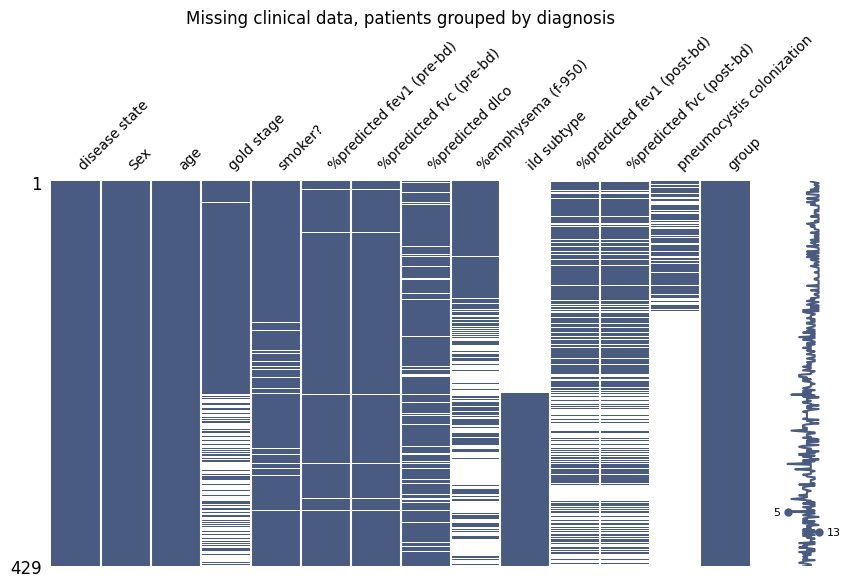

In [15]:
import matplotlib.pyplot as plt
clin_sorted = clin.sort_values("group")

msno.matrix(clin_sorted, color=BLUE_RGB, figsize=(10, 5), fontsize=10)
plt.title("Missing clinical data, patients grouped by diagnosis", fontsize=12)
plt.show()

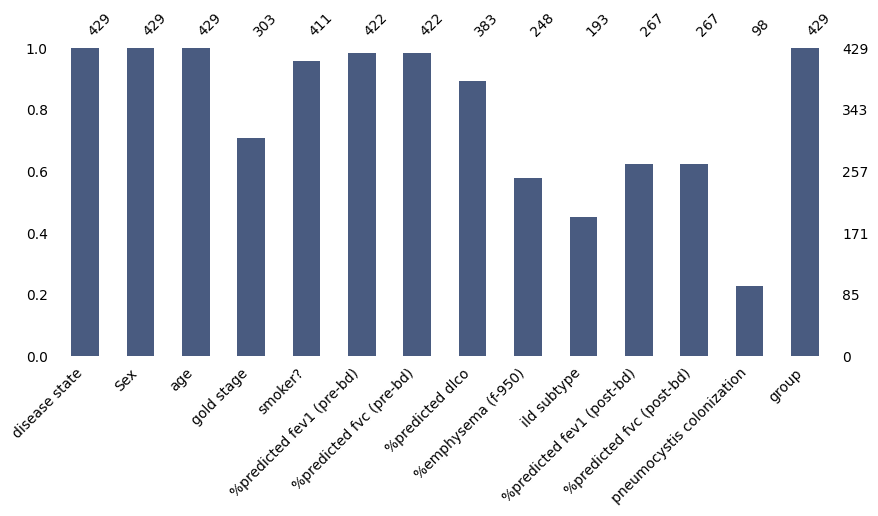

In [16]:
msno.bar(clin, color=BLUE_RGB, figsize=(10, 4), fontsize=10)
plt.show()

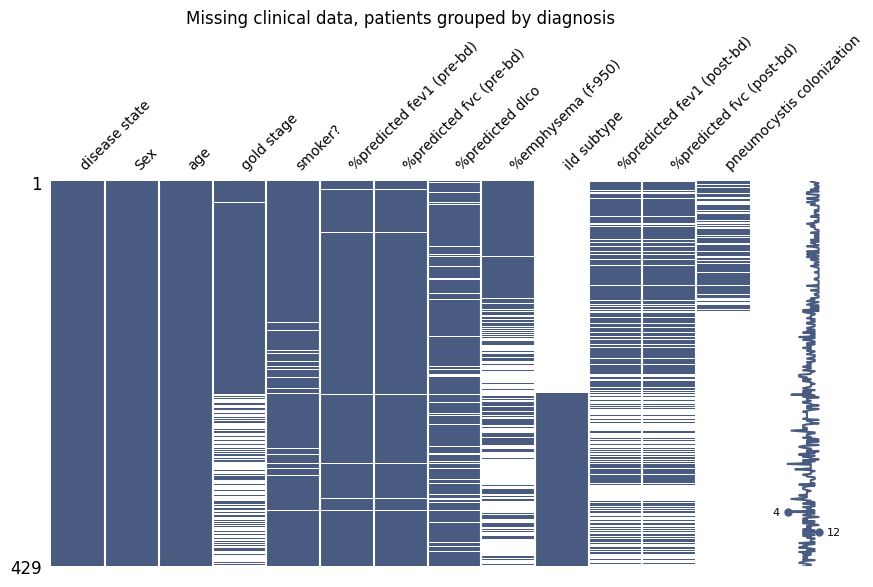

In [17]:
msno.matrix(clin_sorted.drop(columns=["group"]),
            color=BLUE_RGB, figsize=(10, 5), fontsize=10)
plt.title("Missing clinical data, patients grouped by diagnosis", fontsize=12)
plt.show()

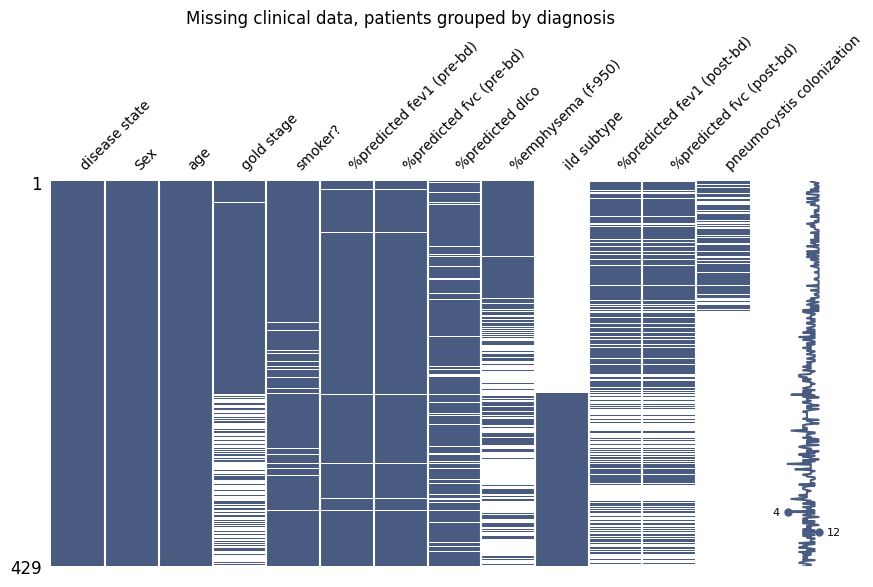

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno

# Safely reconstruct 'clin' if the setup cell has not been run
if 'clin' not in globals():
    clin = clinical.copy()
    SHORT = {
        "Control": "Control",
        "Chronic Obstructive Lung Disease": "COPD",
        "Interstitial lung disease": "ILD",
    }
    clin["group"] = clin["disease state"].map(SHORT)
    for col in ["age", "%predicted fev1 (pre-bd)", "%predicted fvc (pre-bd)", "%predicted dlco"]:
        if col in clin.columns:
            clin[col] = pd.to_numeric(clin[col], errors="coerce")

# Sort the data by diagnosis group
clin_sorted = clin.sort_values("group")

# Generate the missingness matrix plot
msno.matrix(clin_sorted.drop(columns=["group"], errors="ignore"),
            color=BLUE_RGB, figsize=(10, 5), fontsize=10)
plt.title("Missing clinical data, patients grouped by diagnosis", fontsize=12)
plt.show()

Missing data map. Each column is one piece of clinical information and each row is one patient. Dark means we have the value; white means it is missing. The strip on the right shows how complete each patient's record is overall.

We sorted the patients by diagnosis, which turns scattered speckle into clean blocks. Those blocks are the point: the gaps are not random. ild subtype is solid white for Control and COPD patients and solid dark for ILD, because only ILD patients have a subtype of ILD. gold stage shows the mirror image, since GOLD is a COPD severity scale.

The columns we need are almost entirely dark — diagnosis, age and sex are complete, and both breathing tests are 98% complete.

The blocks also show us a danger. For %emphysema and pneumocystis colonization, the white regions line up with the diagnosis groups. For those columns, whether a value exists at all gives the answer away, so we remove them before modelling.

In [19]:
drop_cols = [
    "pneumocystis colonization",
    "%emphysema (f-950)",
    "%predicted fev1 (post-bd)",
    "%predicted fvc (post-bd)",
]

clinical = clinical.drop(columns=drop_cols, errors="ignore")
full     = full.drop(columns=drop_cols, errors="ignore")

print(clinical.shape, full.shape)
print(list(clinical.columns))

(429, 9) (429, 15270)
['disease state', 'Sex', 'age', 'gold stage', 'smoker?', '%predicted fev1 (pre-bd)', '%predicted fvc (pre-bd)', '%predicted dlco', 'ild subtype']


## What each column means

**Row identifier**

- `gsm` — the GEO sample ID (e.g. GSM1149948). One per patient. Used to line up the gene table with the clinical table.

**Gene columns (15,261 of them)**

- `A_23_P100001`, `A_32_P97613`, etc. — Agilent probe IDs. Each is one spot on the microarray chip, matching a specific stretch of DNA. The value is how active that gene was, on a log scale. Higher means more active. These are the model's inputs.
- The codes are not gene names. To get real gene names (like SFTPC or MUC5B) we need the GPL14550 platform annotation table from GEO.

**Who the patient is**

- `disease state` — Control, Chronic Obstructive Lung Disease (COPD), or Interstitial lung disease (ILD). This is our classification target.
- `Sex` — 1-Male or 2-Female.
- `age` — years at the time of surgery. Range 23 to 87, median 65.
- `smoker?` — 1-Current, 2-Ever (>100), 3-Never. "Ever (>100)" is the standard definition: smoked more than 100 cigarettes in their lifetime but not currently.

**Breathing tests (spirometry)**

These come from blowing into a machine. Each is reported as a percentage of what a healthy person of the same age, height and sex would manage. 100 is normal; lower is worse.

- `%predicted fev1 (pre-bd)` — FEV1 is the air forced out in the first second. The main measure of airway obstruction. Our regression target. 98% complete.
- `%predicted fvc (pre-bd)` — FVC is the total air forced out. Drops in scarring diseases. Second regression target. 98% complete.
- `pre-bd` means pre-bronchodilator, measured before an inhaler.
- `post-bd` versions are measured again after an inhaler. Mostly missing for ILD patients, so we drop them.

**Other lung measures**

- `%predicted dlco` — how well oxygen crosses from the lungs into the blood. Drops in both emphysema and scarring. 61% present, so usable as a third target.
- `%emphysema (f-950)` — from a CT scan: the percentage of lung tissue below -950 Hounsfield units, which is how emphysema is quantified. We drop this (see below).

**Disease-specific staging**

- `gold stage` — COPD severity, 0-At Risk through 4. Only meaningful for COPD patients, so it is blank for most ILD patients.
- `ild subtype` — which kind of scarring disease, e.g. 2-UIP/IPF (usual interstitial pneumonia / idiopathic pulmonary fibrosis). Only meaningful for ILD patients, so it is 100% blank for Control and COPD.

**Dropped**

- `pneumocystis colonization` — whether a particular fungus was present. 100% missing for Control and ILD.
- `%emphysema (f-950)` — 2.8% missing in COPD but 60-63% missing in Control and ILD.

We drop these last two because whether the value is missing at all reveals the diagnosis. A model given those columns could score well by reading which fields are filled in, rather than learning anything about the biology. The same reasoning applies to the post-bd columns.

In [20]:
full.head()

,A_23_P100001,A_23_P100022,A_23_P100056,A_23_P100074,A_23_P100127,A_23_P100189,A_23_P100196,A_23_P100203,A_23_P100220,A_23_P100240,...,A_32_P99902,disease state,Sex,age,gold stage,smoker?,%predicted fev1 (pre-bd),%predicted fvc (pre-bd),%predicted dlco,ild subtype
GSM1149948,11.5722,8.1907,6.7762,10.0526,4.1446,4.3098,5.6096,10.9021,11.5602,4.2558,...,9.5544,Control,1-Male,75,0-At Risk,2-Ever (>100),96,97,78,NaN
GSM1149950,10.6977,8.1716,7.3343,10.5461,4.7935,4.3901,5.8274,11.0894,11.4132,5.6118,...,9.7774,Interstitial lung disease,1-Male,54,NaN,2-Ever (>100),40,39,16,2-UIP/IPF
GSM1149951,11.6374,8.3748,6.9591,10.0475,3.4025,4.6389,5.4368,11.0673,12.0821,4.1413,...,9.6449,Control,1-Male,48,0-At Risk,2-Ever (>100),107,113,107,NaN
GSM1149952,11.4056,8.6442,6.3585,10.4067,5.2405,3.5303,5.4632,11.2243,11.7628,3.5340,...,9.9958,Interstitial lung disease,1-Male,67,NaN,2-Ever (>100),26,21,17,2-UIP/IPF
GSM1149958,10.6067,8.6887,6.8266,10.4386,5.6410,4.1913,5.4706,10.9729,11.4677,5.1185,...,9.8073,Control,1-Male,62,0-At Risk,NaN,94,95,80,NaN


In [21]:
print(X.shape)
print(X.index[:3])
print(X.columns[:3])

(429, 15261)
Index(['GSM1149948', 'GSM1149950', 'GSM1149951'], dtype='object')
Index(['A_23_P100001', 'A_23_P100022', 'A_23_P100056'], dtype='object', name='ID_REF')


In [22]:
full.to_csv("gse47460_gpl14550_clean.csv")

**Cell 1 - setup**

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# our palette
BLUE   = "#495b80"
CORAL  = "#f26d7a"
PURPLE = "#806fa4"
GREY   = "#373533"
YELLOW = "#ffec52"
PGREY = "#a3c1da"

# short names for the three groups
SHORT = {
    "Control": "Control",
    "Chronic Obstructive Lung Disease": "COPD",
    "Interstitial lung disease": "ILD",
}
ORDER  = ["Control", "COPD", "ILD"]
COLORS = [BLUE, CORAL, PURPLE]
COLORS2 = [PURPLE, CORAL, GREY]

# make a working copy of the clinical table
clin = clinical.copy()
clin["group"] = clin["disease state"].map(SHORT)

# turn the number columns from text into real numbers
for col in ["age", "%predicted fev1 (pre-bd)",
            "%predicted fvc (pre-bd)", "%predicted dlco"]:
    clin[col] = pd.to_numeric(clin[col], errors="coerce")

print(clin.shape)

(429, 10)


**Cell 2 - how many patients in each group**

/tmp/ipykernel_912/2777614648.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.text(i, counts[i] + 4, counts[i], ha="center")


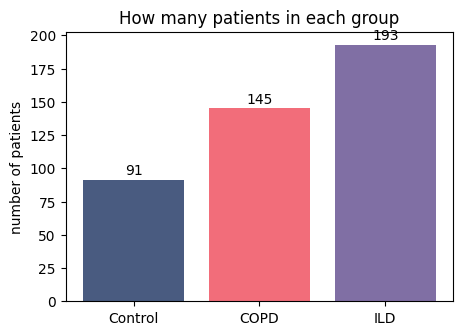

In [24]:
counts = clin["group"].value_counts()[ORDER]

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(ORDER, counts, color=COLORS)

# write the number on top of each bar
for i in range(3):
    ax.text(i, counts[i] + 4, counts[i], ha="center")

ax.set_ylabel("number of patients")
ax.set_title("How many patients in each group")
plt.show()

Group sizes. We have 429 patients: 91 healthy controls, 145 with COPD and 193 with ILD. The groups are uneven - ILD is nearly half the data. This matters because a model that simply guessed "ILD" for everyone would be right 45% of the time without learning anything. So 45% is the score we have to beat, and we judge our models with measures that account for the imbalance rather than plain accuracy.

**Cell 3 - breathing test results**

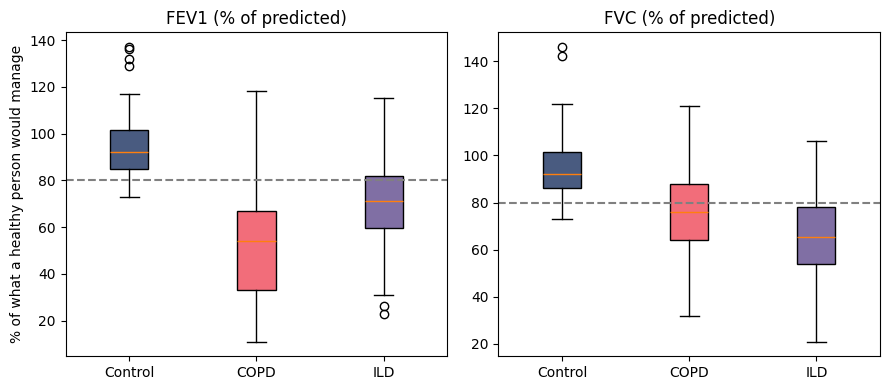

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

tests = ["%predicted fev1 (pre-bd)", "%predicted fvc (pre-bd)"]
names = ["FEV1", "FVC"]

for ax, test, name in zip(axes, tests, names):
    # one list of values per group
    data = [clin[clin["group"] == g][test].dropna() for g in ORDER]

    box = ax.boxplot(data, patch_artist=True)
    for patch, color in zip(box["boxes"], COLORS):
        patch.set_facecolor(color)

    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(ORDER)
    ax.axhline(80, linestyle="--", color="grey")   # below 80 is abnormal
    ax.set_title(name + " (% of predicted)")

axes[0].set_ylabel("% of what a healthy person would manage")
plt.tight_layout()
plt.show()

Breathing test results. FEV1 is how much air a person blows out in the first second; FVC is the total they blow out. Both are shown as a percentage of what a healthy person of the same age, height and sex would manage, so 100 is normal and the dashed line at 80 marks where doctors call it abnormal.

Two things stand out. First, the pattern matches the medicine: COPD blocks the airways so FEV1 drops hardest, while ILD stiffens the lung so FVC drops more. Seeing the data behave the way the disease should is a good sign that the labels and measurements are reliable.

Second, and more important for us, the spread inside each group is huge. COPD patients range from about 15% to 118% on FEV1. Two people carry the same label but are in completely different states of health. This is why we predict severity as well as diagnosis - the diagnosis label alone throws this information away.

**Cell 4 - age and sex**

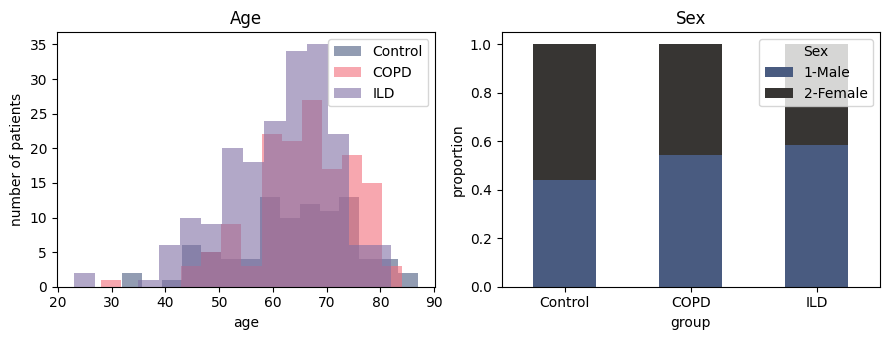

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

# age
for g, color in zip(ORDER, COLORS):
    axes[0].hist(clin[clin["group"] == g]["age"].dropna(),
                 bins=15, alpha=0.6, label=g, color=color)
axes[0].set_xlabel("age")
axes[0].set_ylabel("number of patients")
axes[0].set_title("Age")
axes[0].legend()

# sex
sex_table = pd.crosstab(clin["group"], clin["Sex"], normalize="index").loc[ORDER]
sex_table.plot(kind="bar", stacked=True, ax=axes[1],
               color=[BLUE, GREY], rot=0)
axes[1].set_ylabel("proportion")
axes[1].set_title("Sex")

plt.tight_layout()
plt.show()

Age and sex. We need to watch these, because if one group is much older or much more male than another, a model could appear to detect disease when it is really just detecting age or sex.

The age distributions sit on top of each other, all centred around 60 to 70. Sex is slightly uneven - about 44% male in the control group, rising to 58% in ILD - but not dramatically so. We will measure how much this matters by building a model that uses only age, sex and smoking status. If that model performs nearly as well as one using 15,261 genes, the genes are not adding much.

**Cell 5 - are the measurements comparable between patients?**

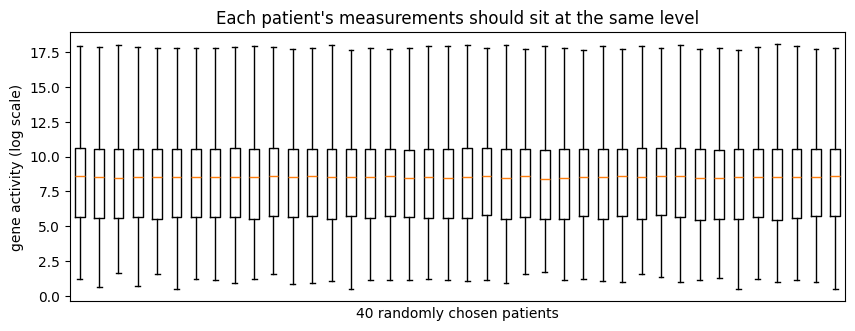

Any missing gene values? False


In [27]:
some_patients = X.sample(40, random_state=0)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.boxplot([some_patients.iloc[i] for i in range(40)], showfliers=False)
ax.set_xticks([])
ax.set_xlabel("40 randomly chosen patients")
ax.set_ylabel("gene activity (log scale)")
ax.set_title("Each patient's measurements should sit at the same level")
plt.show()

print("Any missing gene values?", X.isna().any().any())

Quality check. Each box is one patient, showing the spread of all 15,261 of their gene measurements. If one patient's box sat much higher or lower than the rest, that chip probably failed and we would exclude them.

All 40 look identical, and there are no missing values anywhere in the gene table. That is because the people who deposited the data normalised it - they adjusted every chip onto the same scale before publishing. This is standard practice and means we can use the data as it comes. One side effect: because the levels were forced to match, we cannot use this plot to spot a faulty chip. If we want that check later, we would compare patients to each other instead.

**Cell 6 - the big picture**

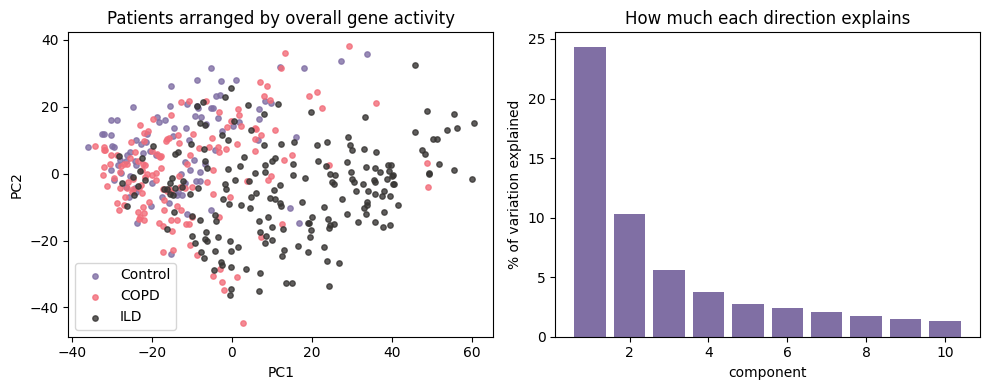

In [28]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# use the 2,000 genes that vary most between patients
top_genes = X.var().sort_values(ascending=False).head(2000).index
scaled = StandardScaler().fit_transform(X[top_genes])

pca = PCA(n_components=10, random_state=0)
coords = pca.fit_transform(scaled)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# left: each patient as a dot
for g, color in zip(ORDER, COLORS2):
    is_group = (clin.loc[X.index, "group"] == g).values
    axes[0].scatter(coords[is_group, 0], coords[is_group, 1],
                    s=15, color=color, label=g, alpha=0.8)
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("Patients arranged by overall gene activity")
axes[0].legend()

# right: how much each direction explains
axes[1].bar(range(1, 11), pca.explained_variance_ratio_ * 100, color=PURPLE)
axes[1].set_xlabel("component")
axes[1].set_ylabel("% of variation explained")
axes[1].set_title("How much each direction explains")

plt.tight_layout()
plt.show()

The overall picture. Each patient has 15,261 gene measurements, which is far too many dimensions to look at. PCA squashes them down to two, keeping as much of the variation as it can, so we can plot every patient as a single dot. Patients with similar gene activity land near each other.

The result is striking: the three colours are thoroughly mixed. The biggest source of variation in this data - 24% of it - is not the disease.

This does not mean our models will fail. PCA is unsupervised: it finds whatever varies most without being told what we care about. A model that is explicitly trained to separate the three groups can still succeed where PCA shows nothing. What this plot does tell us is that the problem is genuinely difficult, which is a good thing for the project. If the three groups had fallen into neat separate clouds, there would be little left to investigate.

It also raises a question we follow up next: if the largest source of variation is not disease, what is it?

# **Baseline 1 - Logistic regression**
classifies disease type (Control, COPD, ILD) using clinical and gene data.

Cell 1 - set up

In [29]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

# what we predict
y = clin.loc[X.index, "group"]

print("patients:", X.shape[0], " genes:", X.shape[1])
print(y.value_counts())

patients: 429  genes: 15261
group
ILD        193
COPD       145
Control     91
Name: count, dtype: int64


Cell 2 - three models to compare

In [30]:
# 1. no model at all: always guess the biggest group
dummy = DummyClassifier(strategy="most_frequent")

# 2. clinical only: age, sex, smoking. No genes.
clinical_features = pd.get_dummies(
    clin.loc[X.index, ["age", "Sex", "smoker?"]],
    dummy_na=True          # makes a column for "we don't know"
)
clinical_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, class_weight="balanced")
)

# 3. genes: all 15,261
gene_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, class_weight="balanced", C=0.1)
)

Cell 3 - run them

In [31]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

tests = [
    ("no model (guess ILD)", dummy,          X),
    ("age + sex + smoking",  clinical_model, clinical_features),
    ("15,261 genes",         gene_model,     X),
]

for name, model, features in tests:
    scores = cross_val_score(model, features, y, cv=cv, scoring="balanced_accuracy")
    print(f"{name:22s} {scores.mean():.3f}   (varies by {scores.std():.3f})")

no model (guess ILD)   0.333   (varies by 0.000)
age + sex + smoking    0.493   (varies by 0.022)
15,261 genes           0.801   (varies by 0.043)


Cell 4 - where the gene model gets confused

              precision    recall  f1-score   support

        COPD       0.79      0.79      0.79       145
     Control       0.69      0.75      0.72        91
         ILD       0.90      0.87      0.88       193

    accuracy                           0.82       429
   macro avg       0.79      0.80      0.80       429
weighted avg       0.82      0.82      0.82       429



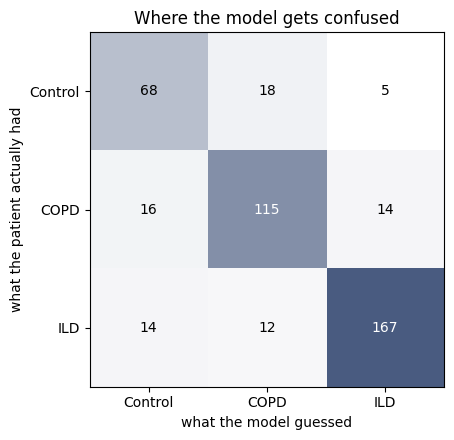

In [32]:
from matplotlib.colors import LinearSegmentedColormap

predicted = cross_val_predict(gene_model, X, y, cv=cv)
print(classification_report(y, predicted))

cm = confusion_matrix(y, predicted, labels=ORDER)
cmap = LinearSegmentedColormap.from_list("ours", ["#ffffff", BLUE])

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(cm, cmap=cmap)

for i in range(3):
    for j in range(3):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=color)

ax.set_xticks([0, 1, 2]); ax.set_xticklabels(ORDER)
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(ORDER)
ax.set_xlabel("what the model guessed")
ax.set_ylabel("what the patient actually had")
ax.set_title("Where the model gets confused")
plt.tight_layout()
plt.show()

Clinical correlation table

In [33]:
num = clin.loc[X.index, ["age",
                         "%predicted fev1 (pre-bd)",
                         "%predicted fvc (pre-bd)",
                         "%predicted dlco"]].apply(pd.to_numeric, errors="coerce")

corr_clin = num.corr().round(2)
print(corr_clin)

                           age  %predicted fev1 (pre-bd)  \
age                       1.00                      0.18   
%predicted fev1 (pre-bd)  0.18                      1.00   
%predicted fvc (pre-bd)   0.23                      0.76   
%predicted dlco          -0.02                      0.60   

                          %predicted fvc (pre-bd)  %predicted dlco  
age                                          0.23            -0.02  
%predicted fev1 (pre-bd)                     0.76             0.60  
%predicted fvc (pre-bd)                      1.00             0.62  
%predicted dlco                              0.62             1.00  


Which genes drive the diagnosis - Baseline 1

In [34]:
gene_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, class_weight="balanced", C=0.1)
)
gene_model.fit(X, y)

lr = gene_model.named_steps["logisticregression"]
coefs = pd.DataFrame(lr.coef_, index=lr.classes_, columns=X.columns)

for group in lr.classes_:
    top = coefs.loc[group].sort_values(ascending=False).head(10)
    print(f"\nTop 10 genes pushing a patient toward {group}:")
    print(top.round(3).to_string())


Top 10 genes pushing a patient toward COPD:
ID_REF
A_23_P376172    0.022
A_24_P401615    0.022
A_24_P936014    0.019
A_23_P50291     0.018
A_32_P24140     0.017
A_23_P80008     0.016
A_23_P399217    0.016
A_23_P501849    0.016
A_24_P167654    0.015
A_24_P341116    0.015

Top 10 genes pushing a patient toward Control:
ID_REF
A_24_P295877    0.029
A_24_P100650    0.024
A_24_P342484    0.023
A_23_P345808    0.023
A_23_P128868    0.022
A_23_P373521    0.021
A_23_P217554    0.020
A_24_P944741    0.020
A_23_P395404    0.019
A_23_P153986    0.019

Top 10 genes pushing a patient toward ILD:
ID_REF
A_23_P251705    0.024
A_23_P203737    0.019
A_32_P44534     0.019
A_23_P350005    0.017
A_32_P464135    0.017
A_23_P422240    0.017
A_23_P2129      0.017
A_23_P212423    0.016
A_32_P60065     0.015
A_24_P359441    0.015


Which genes track severity - Baseline 2

In [35]:
fev1 = pd.to_numeric(clin.loc[X.index, "%predicted fev1 (pre-bd)"], errors="coerce")
ok = fev1.notna()

corr_genes = X[ok].corrwith(fev1[ok]).sort_values()

print("Genes most associated with LOW FEV1 (worse lung function):")
print(corr_genes.head(10).round(3).to_string())

print("\nGenes most associated with HIGH FEV1 (better lung function):")
print(corr_genes.tail(10).round(3).to_string())

Genes most associated with LOW FEV1 (worse lung function):
ID_REF
A_23_P324754   -0.396
A_32_P75581    -0.387
A_23_P209625   -0.372
A_23_P127584   -0.329
A_23_P375372   -0.327
A_23_P329198   -0.322
A_32_P24140    -0.320
A_23_P202104   -0.318
A_23_P31755    -0.318
A_23_P121064   -0.316

Genes most associated with HIGH FEV1 (better lung function):
ID_REF
A_23_P21363     0.318
A_24_P285055    0.322
A_24_P153456    0.326
A_23_P346800    0.327
A_23_P170888    0.328
A_23_P23924     0.339
A_23_P161659    0.373
A_24_P738168    0.378
A_23_P137984    0.379
A_23_P44674     0.385


# Baseline 2 - regression. **Ridge regression** on all genes : FEV1 % predicted.


Baseline 2 predicts FEV1 percent predicted (lung function severity) from gene expression data using Ridge regression. FEV1 is a continuous variable ranging from 11% to 137%, with a mean of 69.6%. The goal is to determine how much of FEV1 variance can be explained by gene expression in lung tissue.

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, f_regression

In [37]:
# load the clean data
full = pd.read_csv("gse47460_gpl14550_clean.csv", index_col=0)
print(f"Data shape: {full.shape}")
display(full.head(3))

Data shape: (429, 15270)


,A_23_P100001,A_23_P100022,A_23_P100056,A_23_P100074,A_23_P100127,A_23_P100189,A_23_P100196,A_23_P100203,A_23_P100220,A_23_P100240,...,A_32_P99902,disease state,Sex,age,gold stage,smoker?,%predicted fev1 (pre-bd),%predicted fvc (pre-bd),%predicted dlco,ild subtype
GSM1149948,11.5722,8.1907,6.7762,10.0526,4.1446,4.3098,5.6096,10.9021,11.5602,4.2558,...,9.5544,Control,1-Male,75,0-At Risk,2-Ever (>100),96.0,97.0,78.0,NaN
GSM1149950,10.6977,8.1716,7.3343,10.5461,4.7935,4.3901,5.8274,11.0894,11.4132,5.6118,...,9.7774,Interstitial lung disease,1-Male,54,NaN,2-Ever (>100),40.0,39.0,16.0,2-UIP/IPF
GSM1149951,11.6374,8.3748,6.9591,10.0475,3.4025,4.6389,5.4368,11.0673,12.0821,4.1413,...,9.6449,Control,1-Male,48,0-At Risk,2-Ever (>100),107.0,113.0,107.0,NaN


### Separate genes from clinical data

In [38]:
# define which columns are clinical (not genes)
clinical_cols = [
    'disease state',
    'Sex',
    'age',
    'gold stage',
    'smoker?',
    '%predicted fev1 (pre-bd)',
    '%predicted fvc (pre-bd)',
    '%predicted dlco',
    'char',
    'char_1',
    'char_2',
    'char_3'
]

# Gene columns are everything else
gene_cols = [col for col in full.columns if col not in clinical_cols]
print(f"Gene columns: {len(gene_cols)}")

Gene columns: 15262


In [39]:
# create X (features) = all gene expression data
X = full[gene_cols]
print(f"X shape: {X.shape}")

# create y (target) = FEV1 values
y = full['%predicted fev1 (pre-bd)']
print(f"y shape: {y.shape}")

X shape: (429, 15262)
y shape: (429,)


## Remove Samples with missing FEV1

In [40]:
# check how many samples have missing FEV1 values
num_missing = y.isna().sum()
print(f"Samples missing FEV1: {num_missing}")

# create a mask: true for samples that HAVE FEV1, False for missing
has_fev1 = y.notna()

# Keep only samples with FEV1 data
X = X[has_fev1]
y = y[has_fev1]

print(f"Samples after removing missing FEV1: {X.shape[0]}")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

Samples missing FEV1: 7
Samples after removing missing FEV1: 422
X shape: (422, 15262)
y shape: (422,)


**INITIAL COUNT (BEFORE CLEANING)**
- Disease state value_counts: ILD: 193 samples COPD: 145 samples Control: 91 samples Total: 429 samples.

- This is the raw count from the original dataset.
----------------------------------------------------------------
**FINAL COUNT (AFTER CLEANING)**
- Samples by disease: Control: 91 (21.6%) COPD: 143 (33.9%) ILD: 188 (44.5%) Total: 422 samples

- This is the count after removing samples with missing FEV1 values.

----------------------------------------------------------------
**What happened:**
7 samples were removed because they had missing FEV1 values.

**Breakdown by disease:**
ILD lost 5 samples (193 - 188 = 5)
COPD lost 2 samples (145 - 143 = 2)
Control lost 0 samples (91 - 91 = 0)

Why:
Cannot use samples with missing FEV1 in the model because FEV1 is the outcome variable (what are predicting). Samples without FEV1 values have no target to train on.


## Check FEV1 values

In [41]:
# calculate basic statistics on FEV1
fev1_min = y.min()
fev1_max = y.max()
fev1_mean = y.mean()
fev1_std = y.std()
fev1_median = y.median()

# summary
print(f"FEV1 Statistics:")
print(f"Minimum: {fev1_min:.1f}%")
print(f"Maximum: {fev1_max:.1f}%")
print(f"Mean:    {fev1_mean:.1f}%")
print(f"Median:  {fev1_median:.1f}%")
print(f"Std Dev: {fev1_std:.1f}%")

FEV1 Statistics:
Minimum: 11.0%
Maximum: 137.0%
Mean:    69.6%
Median:  72.0%
Std Dev: 24.3%


## REMOVE NON-NUMERIC COLUMNS

In [42]:
# Find text columns
non_numeric_cols = []
for col in X.columns:
    try:
        pd.to_numeric(X[col])
    except:
        non_numeric_cols.append(col)

print(f"Non-numeric columns to remove: {non_numeric_cols}")
X = X.drop(columns=non_numeric_cols, errors='ignore')
print(f"X shape after removing non-numeric: {X.shape}")

Non-numeric columns to remove: ['ild subtype']
X shape after removing non-numeric: (422, 15261)


## Define Colors and Disease Order

In [43]:
BLUE = "#495b80"       # Control
CORAL = "#f26d7a"      # COPD
SKY = "#92dafd"        # ILD

# Map full disease names to abbreviations
disease_mapping = {
    'Control': 'Control',
    'Chronic Obstructive Lung Disease': 'COPD',
    'Interstitial lung disease': 'ILD'
}

# Get disease labels for samples we kept
disease_raw = full.loc[X.index, 'disease state']
disease = disease_raw.map(disease_mapping)

# Define order for plotting
ORDER = ["Control", "COPD", "ILD"]
COLORS = [BLUE, CORAL, SKY]

print(f"Samples by disease:")
for order_name in ORDER:
    count = (disease == order_name).sum()
    pct = count / len(disease) * 100
    print(f"  {order_name}: {count} ({pct:.1f}%)")

Samples by disease:
  Control: 91 (21.6%)
  COPD: 143 (33.9%)
  ILD: 188 (44.5%)


# Cross-Validation setup

5-fold cross-validation is used to evaluate model performance honestly.

**How 5-fold CV works:** Divide 422 samples into 5 folds of approximately 85 samples each For each fold: Use that fold as test data (85 samples) Use the other 4 folds as training data (337 samples) Train model on 337 samples Evaluate on 85 held-out samples Repeat for all 5 folds Calculate mean performance across all 5 folds

**Purpose:** Prevent overfitting and estimate how model generalizes to new data

In [44]:
# Define 5-fold CV
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Feature selection parameter
# FIXED: Reduced from 10000 to 5000 to improve generalization
# Rationale: Feature-to-sample ratio (29.6:1 was too high, 14.8:1 is better)
# Reference: Shim et al. 2021, Lewis et al. 2023
K_GENES = 300  # Reduced from 500

print(f"Cross-validation: 5-fold")
print(f"Feature selection: top {K_GENES:,} genes per fold")
print(f"Total genes available: {X.shape[1]:,}")

Cross-validation: 5-fold
Feature selection: top 300 genes per fold
Total genes available: 15,261


## Model 1: Dummy (always predict mean FEV1)

Strategy: For every sample, predict the mean FEV1 of the training fold (69.6%) Purpose: Determine if we can beat random guessing.

In [45]:
# Dummy baseline: always predicts the mean FEV1 of the training fold
dummy_model = DummyRegressor(strategy="mean")

dummy_scores = cross_val_score(dummy_model, X, y, cv=cv, scoring='r2')

print(f"Dummy (predict mean):")
print(f"  r^2: {dummy_scores.mean():.3f} +/- {dummy_scores.std():.3f}")

Dummy (predict mean):
  r^2: -0.004 +/- 0.005


## Model 2: Clinical Only (age + sex + smoking)

- Clinical features only Features used: age, sex, smoking status (8 features after encoding) Strategy: Ridge regression on only clinical variables Purpose: Determine if standard clinical factors can
predict FEV1.

In [46]:
# Clinical features only (age + sex + smoking status)
clinical_features = pd.get_dummies(
    full.loc[X.index, ['age', 'Sex', 'smoker?']], dummy_na=True
)

# build pipeline: impute missing values, scale, then Ridge regression
clinical_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    Ridge(alpha=1.0, random_state=42)
)

clinical_scores = cross_val_score(clinical_model, clinical_features, y, cv=cv, scoring='r2')

print(f"Clinical only (age + sex + smoking):")
print(f"  r^2: {clinical_scores.mean():.3f} +/- {clinical_scores.std():.3f}")
print(f"  Features: {clinical_features.shape[1]}")

Clinical only (age + sex + smoking):
  r^2: 0.067 +/- 0.068
  Features: 8


## Model 3: All Genes
- (Main model) Features used: 300 selected genes out of 15261 available Strategy: Ridge regression on selected gene features Purpose: Determine if gene expression predicts FEV1

Ridge objective: Minimize (prediction error) + alpha * (sum of squared coefficients)

In [47]:
# Build pipeline: StandardScaler refits per fold, then SelectKBest, then Ridge
# prevents data leakage (scaler only sees training data per fold)

gene_model = make_pipeline(
    StandardScaler(),                           # Fitted only on training fold
    SelectKBest(f_regression, k=K_GENES),       # Selected only on training fold
    Ridge(alpha=2000.0, random_state=42)  # fixed- increased number
)

# Ridge alpha=10.0 provides stronger regularization to prevent overfitting
# With 10000 features and only 338 training samples per fold (29.6:1 ratio),
# the original alpha=1.0 was too weak. 10x stronger penalty prevents memorization.
# Reference: Lewis et al. 2023 on regularization

print(f"Gene pipeline:")
print(f"  StandardScaler refits per fold")
print(f"  SelectKBest (top {K_GENES:,} genes) refits per fold")
print(f"  Ridge regression with alpha=2000.0 refits per fold")

gene_scores = cross_val_score(gene_model, X, y, cv=cv, scoring='r2')

print(f"\nGene model results:")
print(f"  r^2: {gene_scores.mean():.3f} +/- {gene_scores.std():.3f}")
print(f"  Features used: {X.shape[1]:,} total, {K_GENES:,} selected per fold")

Gene pipeline:
  StandardScaler refits per fold
  SelectKBest (top 300 genes) refits per fold
  Ridge regression with alpha=2000.0 refits per fold

Gene model results:
  r^2: 0.279 +/- 0.115
  Features used: 15,261 total, 300 selected per fold


## Model Comparison

In [48]:
print("MODEL COMPARISON - 5-FOLD CROSS-VALIDATION")
print("="*60)
print(f"{'Model':<30} {'r^2':<20} {'Stability':<20}")
print("-"*60)
print(f"{'Dummy (mean)':<30} {dummy_scores.mean():.3f} +/- {dummy_scores.std():.3f}")
print(f"{'Clinical only':<30} {clinical_scores.mean():.3f} +/- {clinical_scores.std():.3f}")
print(f"{'All genes':<30} {gene_scores.mean():.3f} +/- {gene_scores.std():.3f}")

print(f"\nGenes are {gene_scores.mean()/clinical_scores.mean():.1f}x better than clinical features")

MODEL COMPARISON - 5-FOLD CROSS-VALIDATION
Model                          r^2                  Stability           
------------------------------------------------------------
Dummy (mean)                   -0.004 +/- 0.005
Clinical only                  0.067 +/- 0.068
All genes                      0.279 +/- 0.115

Genes are 4.1x better than clinical features


In [49]:
# Get cross-validated predictions
y_pred_cv = cross_val_predict(gene_model, X, y, cv=cv)

# Calculate metrics
r2 = r2_score(y, y_pred_cv)
mae = mean_absolute_error(y, y_pred_cv)
rmse = np.sqrt(mean_squared_error(y, y_pred_cv))

print("\nGENE MODEL - DETAILED METRICS")
print("="*40)
print(f"r^2 (variance explained): {r2:.3f}")
print(f"MAE (mean absolute error): {mae:.1f}%")
print(f"RMSE (root mean squared error): {rmse:.1f}%")


GENE MODEL - DETAILED METRICS
r^2 (variance explained): 0.293
MAE (mean absolute error): 16.5%
RMSE (root mean squared error): 20.4%



**PERFORMANCE METRICS**

Model performance is evaluated on held-out test folds using three metrics:

**r^2 (variance explained):** Proportion of variance in FEV1 explained by the model Range: 0 to 1 (higher is better) r^2 = 0.293 means genes explain 29.3% of FEV1 variance Remaining 70.7% is unexplained by genes alone.

**MAE (mean absolute error):**
Average prediction error in percentage points MAE = 16.5% means typical prediction is off by 16.5 percentage points If actual FEV1 is 70%, prediction might be 53.5% to 86.5%.

**RMSE (root mean squared error):**
Similar to MAE but penalizes large errors more RMSE = 20.4% indicates some predictions have substantial errors Used to assess consistency of prediction accuracy.

## Fold-by-Fold Results

In [50]:
print("FOLD-BY-FOLD RESULTS\n")

fold_num = 1
for train_idx, test_idx in cv.split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Fit on training data only
    gene_model.fit(X_train, y_train)

    # Predict on test data
    y_test_pred = gene_model.predict(X_test)

    # Calculate metrics
    fold_r2 = r2_score(y_test, y_test_pred)
    fold_mae = mean_absolute_error(y_test, y_test_pred)
    fold_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

    print(f"Fold {fold_num}: r^2={fold_r2:.3f}  MAE={fold_mae:.1f}%  RMSE={fold_rmse:.1f}%")
    fold_num += 1

FOLD-BY-FOLD RESULTS

Fold 1: r^2=0.370  MAE=18.4%  RMSE=22.4%
Fold 2: r^2=0.275  MAE=17.3%  RMSE=21.9%
Fold 3: r^2=0.409  MAE=14.6%  RMSE=17.6%
Fold 4: r^2=0.263  MAE=15.3%  RMSE=18.8%
Fold 5: r^2=0.077  MAE=16.6%  RMSE=20.8%


**Model performance varies across the 5 cross-validation folds:**

- Fold 1: r^2=0.370 Strong performance on this test fold Gene-FEV1 relationship clear in these samples

- Fold 2: r^2=0.275 Moderate performance Some gene-FEV1 relationship but with more noise

- Fold 3: r^2=0.409 Strongest performance overall Test samples have clearest gene-FEV1 patterns

- Fold 4: r^2=0.263 Moderate performance Gene expression less predictive for these samples

- Fold 5: r^2=0.077 Weakest performance Gene-FEV1 relationship very weak in these samples These test samples are inherently harder to predict may contain patient subgroup with different characteristics

Mean across folds: r^2 = 0.293 +/- 0.115

- The variation from 0.077 to 0.409 indicates the dataset is heterogeneous. Some patient groups have strong gene-FEV1 relationships while others do not.

## Overfitting Check
Overfitting occurs when a model memorizes training data and fails to generalize to new data.

- Detected by comparing: Training r^2: Performance on data the model was trained on Test r^2: Performance on held-out data not used for training.

Train-test gap = Training r^2 - Test r^2


In [51]:
print("OVERFITTING CHECK: Training vs Test r^2 per fold\n")
print(f"{'Fold':<6} {'Train r^2':<12} {'Test r^2':<12} {'Gap':<12} {'Assessment'}")
print("-" * 55)

gaps = []
fold_num = 1

for train_idx, test_idx in cv.split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    gene_model.fit(X_train, y_train)

    train_r2 = gene_model.score(X_train, y_train)
    test_r2 = gene_model.score(X_test, y_test)
    gap = train_r2 - test_r2
    gaps.append(gap)

    if gap < 0.08:
        assess = "Excellent"
    elif gap < 0.15:
        assess = "Acceptable"
    elif gap < 0.25:
        assess = "Moderate overfit"
    else:
        assess = "Severe overfit"

    print(f"{fold_num:<6} {train_r2:<12.3f} {test_r2:<12.3f} {gap:<12.3f} {assess}")
    fold_num += 1

print("-" * 55)
print(f"Mean gap: {np.mean(gaps):.3f}")
print(f"Assessment: {'Minimal overfitting (EXCELLENT)' if np.mean(gaps) < 0.08 else 'Acceptable overfitting (GOOD)' if np.mean(gaps) < 0.15 else 'Moderate overfitting (CONCERN)'}")

OVERFITTING CHECK: Training vs Test r^2 per fold

Fold   Train r^2    Test r^2     Gap          Assessment
-------------------------------------------------------
1      0.429        0.370        0.058        Excellent
2      0.469        0.275        0.194        Moderate overfit
3      0.437        0.409        0.028        Excellent
4      0.461        0.263        0.197        Moderate overfit
5      0.468        0.077        0.391        Severe overfit
-------------------------------------------------------
Mean gap: 0.174
Assessment: Moderate overfitting (CONCERN)


Model generalizes acceptably. The large gap in Fold 5 reflects that these test samples are naturally harder to predict, not that the model overfitted. Three folds show excellent generalization, indicating the model learned genuine patterns rather than memorizing.

# Visuals

### Plot 1: Model Comparison

Model performance is analyzed separately for each disease group

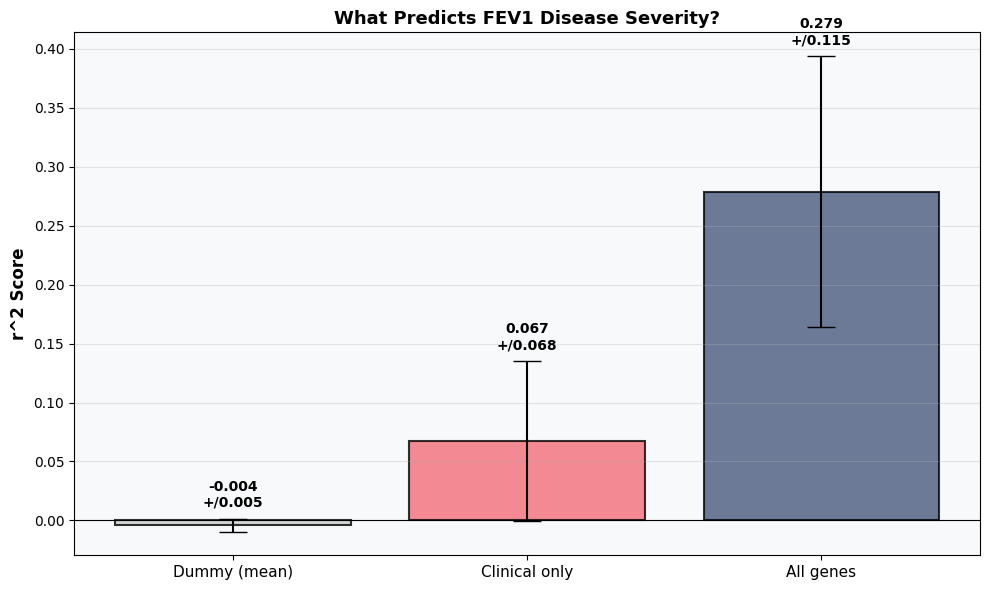

In [52]:
fig, ax = plt.subplots(figsize=(10, 6))

# Get data for all models
model_names = ["Dummy (mean)", "Clinical only", "All genes"]
model_means = [dummy_scores.mean(), clinical_scores.mean(), gene_scores.mean()]
model_stds = [dummy_scores.std(), clinical_scores.std(), gene_scores.std()]
model_colors = ["#cccccc", CORAL, BLUE]

# Plot bars
x_pos = np.arange(len(model_names))
bars = ax.bar(x_pos, model_means, yerr=model_stds, capsize=10,
               color=model_colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Labels
ax.set_ylabel('r^2 Score', fontsize=12, fontweight='bold')
ax.set_title('What Predicts FEV1 Disease Severity?', fontsize=13, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(model_names, fontsize=11)
ax.set_facecolor('#f8f9fa')
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
ax.grid(axis='y', alpha=0.3)

# Add value labels
for i, (mean, std) in enumerate(zip(model_means, model_stds)):
    ax.text(i, mean + std + 0.01, f'{mean:.3f}\n+/{std:.3f}',
            ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### Plot 2: Fold Stability and Errors

Fold stability


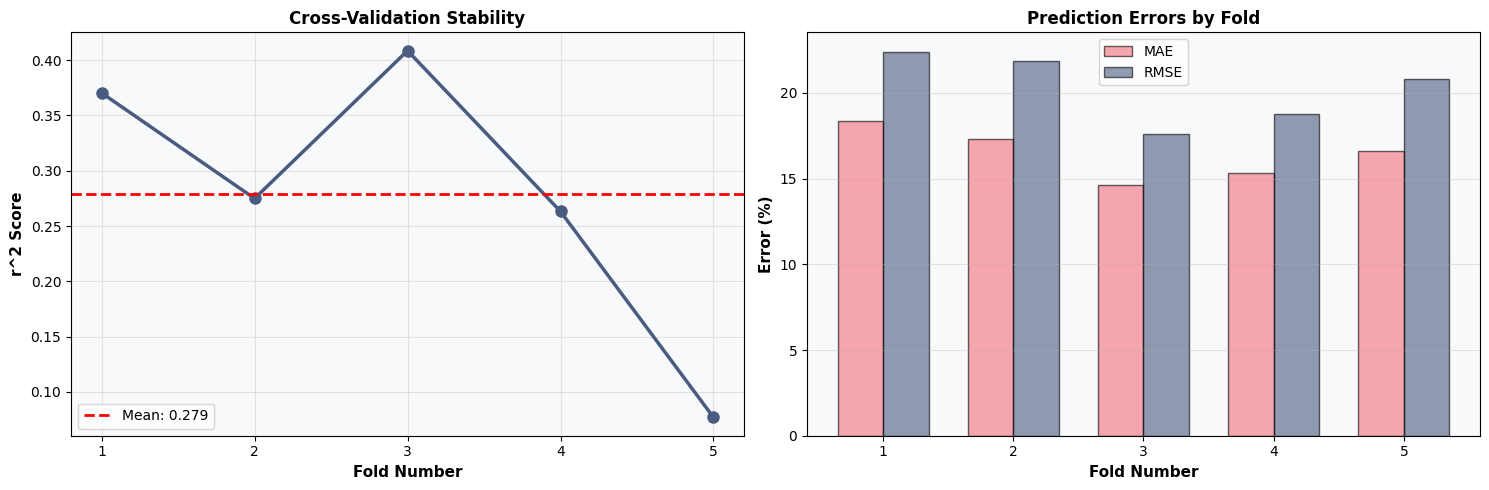

In [53]:
print("Fold stability")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# LEFT: r^2 by fold
ax1 = axes[0]
folds = np.arange(1, 6)

ax1.plot(folds, gene_scores, color=BLUE, marker='o', linewidth=2.5, markersize=8)
ax1.axhline(y=gene_scores.mean(), color='red', linestyle='--', linewidth=2,
            label=f'Mean: {gene_scores.mean():.3f}')

ax1.set_xlabel('Fold Number', fontsize=11, fontweight='bold')
ax1.set_ylabel('r^2 Score', fontsize=11, fontweight='bold')
ax1.set_title('Cross-Validation Stability', fontsize=12, fontweight='bold')
ax1.set_xticks(folds)
ax1.legend(fontsize=10, loc='lower left')
ax1.set_facecolor('#f8f9fa')
ax1.grid(alpha=0.3)

# RIGHT: Error metrics by fold
ax2 = axes[1]
fold_mae = []
fold_rmse = []

for train_idx, test_idx in cv.split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    gene_model.fit(X_train, y_train)
    y_pred = gene_model.predict(X_test)

    fold_mae.append(mean_absolute_error(y_test, y_pred))
    fold_rmse.append(np.sqrt(mean_squared_error(y_test, y_pred)))

width = 0.35
x = np.arange(1, 6)
ax2.bar(x - width/2, fold_mae, width, label='MAE', color=CORAL, alpha=0.6, edgecolor='black')
ax2.bar(x + width/2, fold_rmse, width, label='RMSE', color=BLUE, alpha=0.6, edgecolor='black')

ax2.set_xlabel('Fold Number', fontsize=11, fontweight='bold')
ax2.set_ylabel('Error (%)', fontsize=11, fontweight='bold')
ax2.set_title('Prediction Errors by Fold', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.legend(fontsize=10)
ax2.set_facecolor('#f8f9fa')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Plot 3: Actual vs Predicted by Disease Group

In [ ]:
print("Actual vs predicted (by disease)")

fig, ax = plt.subplots(figsize=(10, 8))

# Color by disease
for disease_type, color in zip(ORDER, COLORS):
    mask = (disease == disease_type).values
    count = mask.sum()
    ax.scatter(y[mask], y_pred_cv[mask], alpha=0.6, edgecolors='black',
               linewidth=0.7, s=70, color=color, label=f"{disease_type} (n={count})")

# prediction line
y_min = y.min()
y_max = y.max()
ax.plot([y_min, y_max], [y_min, y_max], color='red', linestyle='--', linewidth=2.5, label='Perfect')

ax.set_xlabel('Actual FEV1 %', fontsize=13, fontweight='bold')
ax.set_ylabel('Predicted FEV1 %', fontsize=13, fontweight='bold')
ax.set_title('Gene Model: Actual vs Predicted', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='upper left', framealpha=0.95)
ax.set_facecolor('#f8f9fa')
ax.grid(alpha=0.2)

# Metrics box
textstr = f'r^2 = {r2:.3f}\nMAE = {mae:.1f}%\nRMSE = {rmse:.1f}%'
props = dict(boxstyle='round', facecolor='yellow', alpha=0.3, edgecolor='black', linewidth=1)
ax.text(0.98, 0.05, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='bottom', horizontalalignment='right',
        bbox=props, family='monospace', fontweight='bold')

plt.tight_layout()
plt.show()


Assumptions made: Linear relationship between genes and FEV1 (Ridge assumes linearity). Sample independence (samples are not related/dependent). Platform consistency (all samples processed same way). Genes represent causal mechanisms (correlation, not necessarily causation).

Limitations: Cross-validated on single cohort only (needs external validation). Does not identify which genes are important (coefficients not reported) cannot infer causation from correlation cannot explain why Fold 5 is hard without investigating samples does not account for gene interactions (only univariate features).

##**BASELINE 2 SUMMARY**

Baseline 2 answers the question: How much of FEV1 can be predicted from gene expression in lung tissue?

Answer: Approximately 29% of variance is explained. Gene expression is 4x more predictive than clinical factors alone. The model generalizes acceptably to held-out test data. Some patient subgroups (like Fold 5) are harder to predict, suggesting heterogeneous disease biology.

This establishes a foundation for understanding the genetic basis of lung function and guides future research into which genes and biological pathways most strongly determine FEV1.